# Slide 18: one KBM, $\gamma_{\rm code}/\gamma_{\rm GS2}$ against WIDTH (TGLF top, GFTM bottom)

Fusion_PhD-qp5.31 (STEP GK talk, 2 Nov 2026). Format of `fig1c_gamma_ratio_u_shape` in
`notebooks/GFTM_numerics/spr045_single_kbm_width_nbasis.ipynb` (branch `analysis/spr045-single-kbm`, qp5.26) with the user's
changes: raw data only (no Gaussian overlay, no Galerkin arm), TGLF NBASIS 8/16/32, GFTM NBASIS 8/16/32/64.

- The mode: SPR-045 `kbm_free` GS2 sample_0818; $\gamma_{\rm GS2}$ from the cube's `pyroscan.nc` (tail average).
- GFTM: `GFTM/Runs/single_mode_spr045/SPR-045/galF_sample_0818` (stock pointwise field solve, FILTER 0.5; qp5.26).
- TGLF: `TGLF/Runs/single_mode_spr045/SPR-045/fixed_width_f2_sample_0818`, the qp5.26 fixed-width scan rerun at **FILTER 2**
  (TGLF's default, as the dataset slides; qp5.31).
- Each leaf is a cube of copies of the one deck; WIDTH and NBASIS_MAX of every run are per-sample variables of its `pyroscan.nc`.
  Runs with no unstable mode (the mode is lost) are left out of the log axis.

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
# One style for every talk figure (identical in every notebook of this folder; Fusion_PhD-qp5.32). Each PNG fills the right-hand
# ~1060 x 800 px box of a 1920 x 1080 slide, so every figure is 10.6 x 8.0 in at 200 dpi and is saved at exactly that size
# (no bbox_inches="tight"): every PNG is scaled by the same factor on its slide, so text is the same size on every slide.
talk_style = {"figure.figsize": (10.6, 8.0), "savefig.dpi": 200, "savefig.bbox": "standard", "figure.constrained_layout.use": True,
              "font.size": 18, "axes.labelsize": 22, "axes.titlesize": 22, "figure.titlesize": 22,
              "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18, "lines.linewidth": 2.5, "lines.marker": "",
              "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"}
plt.rcParams.update(talk_style)
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
plots_dir = ROOT / "Plots" / "stepgk_20261102"
plots_dir.mkdir(parents=True, exist_ok=True)


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()
import json
import pandas as pd
from pyrokinetics import PyroHypercube

gs2_leaf = Path(os.environ["GK_DATA_ROOT"]).expanduser() / "GS2/Runs/LATIN_HYPERCUBE/SPR-045/kbm_free"
single_root = Path(os.environ["GYRO_DATA_OUTPUT"])     # GyroRun wrote the single-mode scans to the scratch tree
leaves = {"TGLF": single_root / "TGLF/Runs/single_mode_spr045/SPR-045/fixed_width_f2_sample_0818",
          "GFTM": single_root / "GFTM/Runs/single_mode_spr045/SPR-045/galF_sample_0818"}
shown_nbasis = {"TGLF": [8, 16, 32], "GFTM": [8, 16, 32]}     # same NBASIS for both codes (user, 2026-11-01)

gs2_scan = PyroHypercube(pyroscan_json=gs2_leaf / "pyroscan.json", load_base_pyro=True)
gs2_scan.load_gk_output(netcdf_file=gs2_leaf / "pyroscan.nc")
gs2_output = gs2_scan.gk_output.data.set_index(sample="sample_name").sel(sample="sample_0818").pint.dequantify()
gamma_gs2 = float(gs2_output.growth_rate)
print("gamma_GS2", round(gamma_gs2, 4))

gamma_GS2 1.3708


In [2]:
runs = []
for code, leaf in leaves.items():
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    output = scan.gk_output.data.pint.dequantify().squeeze("ky", drop=True)      # one ky per run
    dominant = output.isel(mode=output.growth_rate.fillna(-np.inf).argmax("mode"))   # dominant mode = argmax growth rate
    print(code, json.loads((leaf / "manifest.json").read_text())["code_flags"])   # the leaf-wide settings GyroRun put on the deck
    runs.append(pd.DataFrame(dict(code=code, width=output.WIDTH.values.astype(float), nbasis=output.NBASIS_MAX.values.astype(int),
                                  gamma=dominant.growth_rate.values)))
runs = pd.concat(runs).sort_values(["code", "nbasis", "width"])
print(runs.groupby(["code", "nbasis"]).size().unstack())

TGLF {'FILTER': 2.0, 'THETA_TRAPPED': 0.7, 'NXGRID': 32, 'NMODES': 4, 'USE_BPER': True, 'USE_TRANSPORT_MODEL': False, 'WRITE_WAVEFUNCTION_FLAG': 1, 'FIND_WIDTH': False}


GFTM {'FILTER': 0.5, 'FIND_WIDTH': False, 'NMODES': 4, 'IBRANCH': -1, 'USE_TRANSPORT_MODEL': False, 'USE_BPER': True, 'WRITE_WAVEFUNCTION_FLAG': 1, 'FIELD_GALERKIN': False}
nbasis    2     4     8     16    32    64
code                                      
GFTM    47.0  47.0  47.0  47.0  47.0  47.0
TGLF    47.0  47.0  47.0  47.0  47.0   NaN


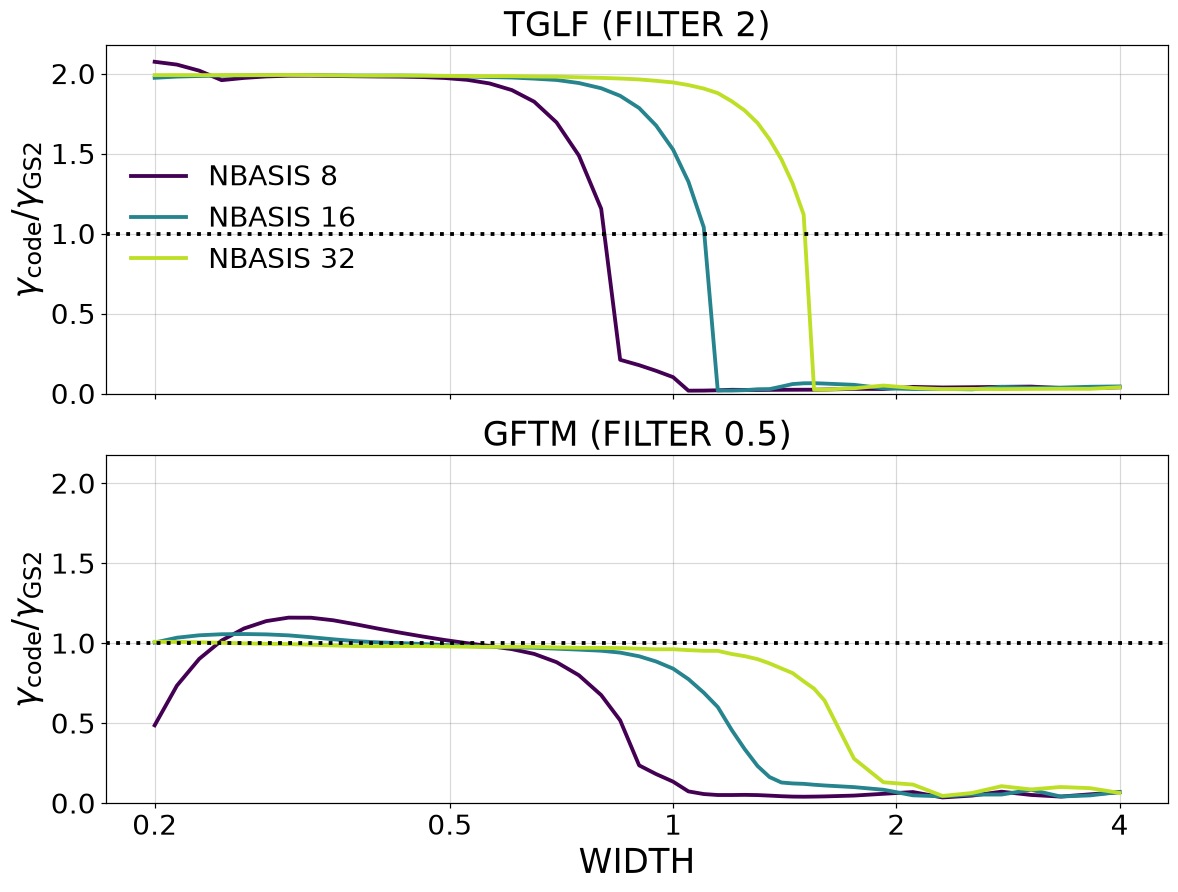

In [3]:
fig, axes = plt.subplots(2, 1, sharex=True, sharey=True)
for ax, code in zip(axes, leaves):
    nbasis_colours = dict(zip(shown_nbasis[code], plt.cm.viridis(np.linspace(0, 0.9, len(shown_nbasis[code])))))
    for nbasis in shown_nbasis[code]:
        unstable = runs[(runs.code == code) & (runs.nbasis == nbasis) & (runs.gamma > 0)]
        ax.plot(unstable.width, unstable.gamma / gamma_gs2, color=nbasis_colours[nbasis], label=f"NBASIS {nbasis}")
    ax.axhline(1, color="k", ls=":")
    ax.set(xscale="log", ylim=(0, None), ylabel=r"$\gamma_{\rm code}/\gamma_{\rm GS2}$",
           title="TGLF (FILTER 2)" if code == "TGLF" else "GFTM (FILTER 0.5)")
axes[0].legend(loc="center left")
axes[1].set_xlabel("WIDTH")
log_xticks(axes[1], [0.2, 0.5, 1, 2, 4])
fig.savefig(plots_dir / "fig_slide18_single_kbm_gamma_ratio.png")
plt.show()